In [1]:
import pandas as pd
from pathlib import Path

In [2]:
data_path = Path("data/raw/processed.cleveland.data")

print("File found:", data_path.exists())

File found: True


In [3]:
df = pd.read_csv(
    data_path,
    header=None,
    na_values="?"
)

df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 303
Columns: 14


In [5]:
df.columns = [
    "age",
    "sex",
    "chest_pain_type",
    "resting_blood_pressure",
    "cholesterol",
    "fasting_blood_sugar",
    "resting_ecg",
    "max_heart_rate",
    "exercise_induced_angina",
    "st_depression",
    "st_slope",
    "major_vessels",
    "thal",
    "disease_status"
]

df.head()

,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,st_slope,major_vessels,thal,disease_status
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
df.isna().sum()

age                        0
sex                        0
chest_pain_type            0
resting_blood_pressure     0
cholesterol                0
fasting_blood_sugar        0
resting_ecg                0
max_heart_rate             0
exercise_induced_angina    0
st_depression              0
st_slope                   0
major_vessels              4
thal                       2
disease_status             0
dtype: int64

In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   age                      303 non-null    float64
 1   sex                      303 non-null    float64
 2   chest_pain_type          303 non-null    float64
 3   resting_blood_pressure   303 non-null    float64
 4   cholesterol              303 non-null    float64
 5   fasting_blood_sugar      303 non-null    float64
 6   resting_ecg              303 non-null    float64
 7   max_heart_rate           303 non-null    float64
 8   exercise_induced_angina  303 non-null    float64
 9   st_depression            303 non-null    float64
 10  st_slope                 303 non-null    float64
 11  major_vessels            299 non-null    float64
 12  thal                     301 non-null    float64
 13  disease_status           303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage

In [9]:
df["disease_status"].value_counts().sort_index()

disease_status
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

In [10]:
df["heart_disease"] = (df["disease_status"] > 0).astype(int)

df["heart_disease"].value_counts().sort_index()

heart_disease
0    164
1    139
Name: count, dtype: int64

In [11]:
df["heart_disease"].value_counts(normalize=True).sort_index().mul(100).round(1)

heart_disease
0    54.1
1    45.9
Name: proportion, dtype: float64

In [12]:
measurement_columns = [
    "age",
    "resting_blood_pressure",
    "cholesterol",
    "max_heart_rate",
    "st_depression"
]

df[measurement_columns].describe().round(2)

,age,resting_blood_pressure,cholesterol,max_heart_rate,st_depression
count,303.00,303.00,303.00,303.00,303.00
mean,54.44,131.69,246.69,149.61,1.04
std,9.04,17.60,51.78,22.88,1.16
min,29.00,94.00,126.00,71.00,0.00
25%,48.00,120.00,211.00,133.50,0.00
50%,56.00,130.00,241.00,153.00,0.80
75%,61.00,140.00,275.00,166.00,1.60
max,77.00,200.00,564.00,202.00,6.20


In [13]:
df.nlargest(5, "cholesterol")[
    ["age", "sex", "cholesterol", "heart_disease"]
]

,age,sex,cholesterol,heart_disease
152,67.0,0.0,564.0,0
48,65.0,0.0,417.0,0
181,56.0,0.0,409.0,1
121,63.0,0.0,407.0,1
173,62.0,0.0,394.0,0


In [14]:
df.loc[
    df[["major_vessels", "thal"]].isna().any(axis=1),
    ["age", "major_vessels", "thal", "heart_disease"]
]

,age,major_vessels,thal,heart_disease
87,53.0,0.0,NaN,0
166,52.0,NaN,3.0,0
192,43.0,NaN,7.0,1
266,52.0,0.0,NaN,1
287,58.0,NaN,7.0,0
302,38.0,NaN,3.0,0


In [15]:
category_columns = [
    "sex",
    "chest_pain_type",
    "fasting_blood_sugar",
    "resting_ecg",
    "exercise_induced_angina",
    "st_slope",
    "major_vessels",
    "thal"
]

for column in category_columns:
    print(column, ":", sorted(df[column].dropna().unique()))

sex : [np.float64(0.0), np.float64(1.0)]
chest_pain_type : [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
fasting_blood_sugar : [np.float64(0.0), np.float64(1.0)]
resting_ecg : [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
exercise_induced_angina : [np.float64(0.0), np.float64(1.0)]
st_slope : [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
major_vessels : [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
thal : [np.float64(3.0), np.float64(6.0), np.float64(7.0)]


In [16]:
for column in category_columns:
    values = sorted(df[column].dropna().unique().tolist())
    print(f"{column}: {values}")

sex: [0.0, 1.0]
chest_pain_type: [1.0, 2.0, 3.0, 4.0]
fasting_blood_sugar: [0.0, 1.0]
resting_ecg: [0.0, 1.0, 2.0]
exercise_induced_angina: [0.0, 1.0]
st_slope: [1.0, 2.0, 3.0]
major_vessels: [0.0, 1.0, 2.0, 3.0]
thal: [3.0, 6.0, 7.0]


In [17]:
df.groupby("heart_disease")["age"].mean().round(1)

heart_disease
0    52.6
1    56.6
Name: age, dtype: float64

In [18]:
df.groupby("heart_disease")["age"].agg(
    ["count", "mean", "median", "min", "max"]
).round(1)

,count,mean,median,min,max
heart_disease,,,,,
0,164,52.6,52.0,29.0,76.0
1,139,56.6,58.0,35.0,77.0


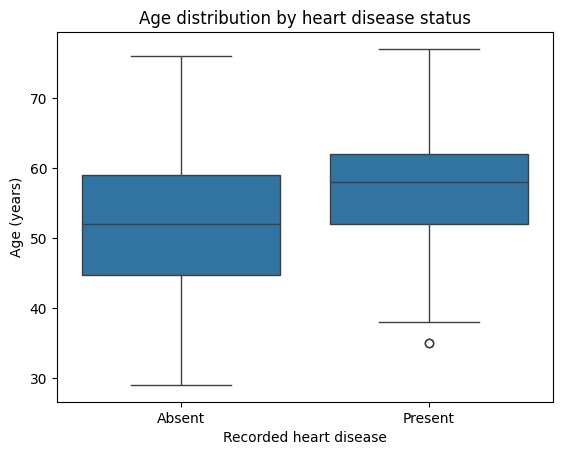

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.boxplot(data=df, x="heart_disease", y="age")

plt.xticks([0, 1], ["Absent", "Present"])
plt.xlabel("Recorded heart disease")
plt.ylabel("Age (years)")
plt.title("Age distribution by heart disease status")
plt.show()

In [20]:
df.groupby("heart_disease")[
    ["resting_blood_pressure", "cholesterol", "max_heart_rate"]
].mean().round(1)

,resting_blood_pressure,cholesterol,max_heart_rate
heart_disease,,,
0,129.2,242.6,158.4
1,134.6,251.5,139.3


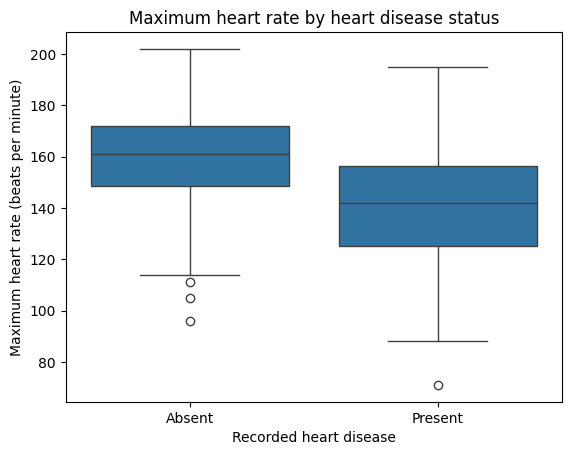

In [21]:
sns.boxplot(data=df, x="heart_disease", y="max_heart_rate")

plt.xticks([0, 1], ["Absent", "Present"])
plt.xlabel("Recorded heart disease")
plt.ylabel("Maximum heart rate (beats per minute)")
plt.title("Maximum heart rate by heart disease status")
plt.show()

In [22]:
df.groupby("heart_disease")["max_heart_rate"].median()

heart_disease
0    161.0
1    142.0
Name: max_heart_rate, dtype: float64

In [23]:
pd.crosstab(
    df["chest_pain_type"],
    df["heart_disease"]
)

heart_disease,0,1
chest_pain_type,,
1.0,16,7
2.0,41,9
3.0,68,18
4.0,39,105


In [24]:
pd.crosstab(
    df["chest_pain_type"],
    df["heart_disease"],
    normalize="index"
).mul(100).round(1)

heart_disease,0,1
chest_pain_type,,
1.0,69.6,30.4
2.0,82.0,18.0
3.0,79.1,20.9
4.0,27.1,72.9


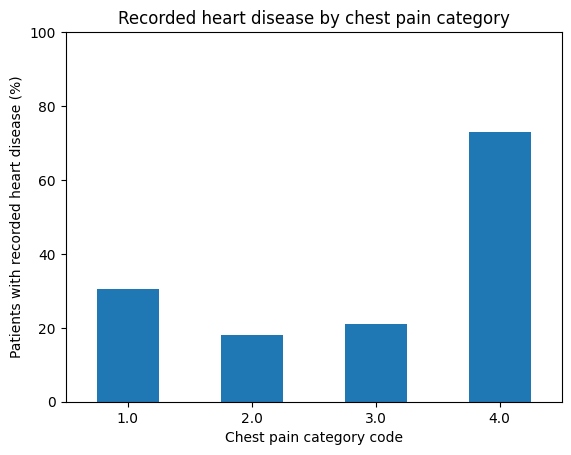

In [25]:
percentages = pd.crosstab(
    df["chest_pain_type"],
    df["heart_disease"],
    normalize="index"
).mul(100)

percentages[1].plot(kind="bar", rot=0)

plt.xlabel("Chest pain category code")
plt.ylabel("Patients with recorded heart disease (%)")
plt.title("Recorded heart disease by chest pain category")
plt.ylim(0, 100)
plt.show()

In [26]:
pd.crosstab(
    df["exercise_induced_angina"],
    df["heart_disease"],
    normalize="index"
).mul(100).round(1)

heart_disease,0,1
exercise_induced_angina,,
0.0,69.1,30.9
1.0,23.2,76.8


In [27]:
pd.crosstab(
    df["exercise_induced_angina"],
    df["heart_disease"],
    margins=True
)

heart_disease,0,1,All
exercise_induced_angina,,,
0.0,141,63,204
1.0,23,76,99
All,164,139,303


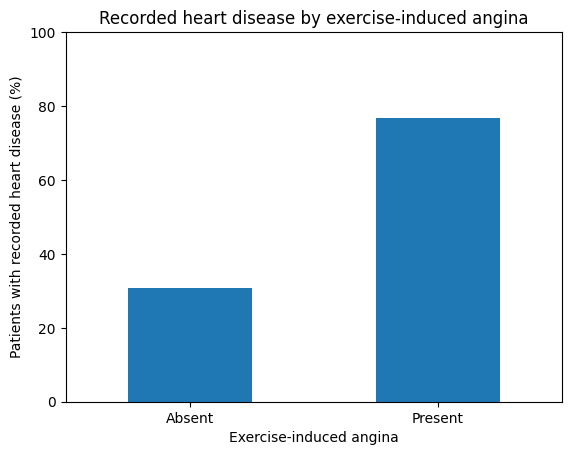

In [28]:
angina_percentages = pd.crosstab(
    df["exercise_induced_angina"],
    df["heart_disease"],
    normalize="index"
).mul(100)

angina_percentages[1].plot(kind="bar", rot=0)

plt.xticks([0, 1], ["Absent", "Present"])
plt.xlabel("Exercise-induced angina")
plt.ylabel("Patients with recorded heart disease (%)")
plt.title("Recorded heart disease by exercise-induced angina")
plt.ylim(0, 100)
plt.show()

## Data audit and exploratory findings

- The Cleveland dataset contains 303 records and 14 original columns.
- No duplicate rows were found.
- Six records have missing values: four in major_vessels and two in thal.
- All records were retained; missing values will be handled during modelling.
- A binary target was created: 0 = disease absent; 1 = disease present.
- Recorded heart disease is present in 139 records (45.9%).
- Median age is 58 years in the disease-present group and 52 in the disease-absent group.
- Median maximum exercise heart rate is 142 bpm in the disease-present group and 161 bpm in the disease-absent group.
- Chest pain category 4 has the highest disease-present proportion (72.9%).
- Recorded heart disease is present in 76.8% of patients with exercise-induced angina, compared with 30.9% without it.
- These findings describe associations in this sample and do not establish causation or population prevalence.